# 08. Baseline Retraining Policies

## Objectives

This notebook runs the three baseline policies of Stage 2
on IEEE-CIS (NoCardID):

1. **T14 – NoRetrain:** the initial model M0 is never updated.
   Output: block-level performance of the static model.
2. **T15 – Periodic:** retrain every 7, 14 or 28 days.
   Output: performance and retraining cost under label
   delays d ∈ {0, 7, 14, 30}.
3. **T16 – Random-k:** retrain at k randomly chosen blocks.
   Output: a random baseline with a controlled retraining
   budget, repeated over many seeds.

The model pipeline (T11), the shared metrics (T12) and the
temporal evaluation engine (T13) are implemented in
`src/modeling.py`, `src/evaluation.py` and `src/policies.py`.

## Protocol

- M0 is trained on the warmup phase (days 1–30).
- Evaluation covers the 21 weekly blocks of the validation
  and test phases (days 31–177). The tail is excluded.
- A retraining decision is made at the start of a block.
  Training rows are selected with the label schedules of
  Step 5: an event is used only if its label is available
  strictly before the decision time and it lies in the
  last W = 60 days.
- A retraining is counted only when the eligible labels
  differ from those of the deployed model. Otherwise the
  model would be identical and the decision is logged as
  `skip_no_new_labels`.
- Category vocabularies are learned from each training
  window only.

## 1. Environment Setup

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "configs" / "dataset.yaml").exists():

    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project root could not be located.")

    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/claude/fraud-retraining


In [2]:
from src.data_loader import load_config, resolve_path
from src.preprocessing import load_feature_config, get_ieee_feature_columns
from src.temporal_split import attach_temporal_index
from src.data_profiling import export_report
from src.modeling import load_policy_config
from src.evaluation import summarize_by_phase
from src.policies import (
    build_model_bank,
    run_policy,
    summarize_cost,
    NoRetrainPolicy,
    PeriodicPolicy,
    RandomKPolicy,
)

### Load configuration

In [3]:
config = load_config()
policy_cfg = load_policy_config()
feature_cfg = load_feature_config()

ieee_cfg = config["datasets"]["ieee_cis"]
sim_cfg = config["simulation"]

exp_cfg = policy_cfg["experiment"]
model_params = policy_cfg["model"]["params"]

WINDOW_DAYS = exp_cfg["window_days"]
DELAYS = sim_cfg["label_delay_days"]
EVAL_PHASES = exp_cfg["evaluation_phases"]

REPORT_DIR = resolve_path(policy_cfg["paths"]["report_dir"])
FIGURE_DIR = resolve_path(policy_cfg["paths"]["figure_dir"])

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Feature set:", exp_cfg["feature_set"])
print("Training window W:", WINDOW_DAYS, "days")
print("Label delays d:", DELAYS)
print("Model parameters:", model_params)

Feature set: NoCardID
Training window W: 60 days
Label delays d: [0, 7, 14, 30]
Model parameters: {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 63, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.5, 'min_child_samples': 100, 'random_state': 42, 'n_jobs': -1, 'verbose': -1}


## 2. Load Input Data

The frozen NoCardID dataset, the temporal index and the
block manifest come from Steps 3–4. Label schedules come
from Step 5.

In [4]:
df = pd.read_parquet(resolve_path(ieee_cfg["processed_nocardid_path"]))

temporal_index = pd.read_parquet(
    resolve_path(config["paths"]["temporal_dir"]) / "ieee_temporal_index.parquet",
    columns=["TransactionID", "TransactionDT", "phase", "block_id"],
)

block_manifest = pd.read_csv(
    resolve_path(config["paths"]["temporal_report_dir"]) / "ieee_block_manifest.csv"
)

features = get_ieee_feature_columns(df, feature_set=exp_cfg["feature_set"])

categorical_columns = [
    column
    for column in feature_cfg["ieee_cis"]["categorical_features"]
    if column in features
]

print("Data shape:", df.shape)
print("Model features:", len(features))
print("Categorical features:", categorical_columns)

assert len(features) == ieee_cfg["expected_nocardid_features"]

Data shape: (590540, 384)
Model features: 381
Categorical features: ['ProductCD', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']


### Evaluation blocks

Only IDs and timestamps are joined with the temporal index
here, to avoid copying the full feature matrix.

In [5]:
block_index = attach_temporal_index(
    df[["TransactionID", "TransactionDT"]],
    temporal_index,
    id_column="TransactionID",
    time_column="TransactionDT",
)

assert block_index["TransactionID"].equals(df["TransactionID"])

eval_mask = block_index["phase"].isin(EVAL_PHASES).to_numpy()

block_ids = block_index["block_id"].to_numpy()

block_manifest = block_manifest.loc[block_manifest["phase"].isin(EVAL_PHASES)]

del temporal_index

print("Evaluation transactions:", int(eval_mask.sum()))
print("Evaluation blocks:", len(block_manifest))

assert sorted(np.unique(block_ids[eval_mask])) == list(range(1, 22))
assert len(block_manifest) == 21

Evaluation transactions: 443845
Evaluation blocks: 21


## 3. Build Model Banks

A retrained model depends only on the decision time, the
label delay d and the window W. It does not depend on which
policy asked for it. One model is therefore trained per
decision time and delay, and all policies reuse it.

This is the expensive step (one LightGBM fit per block and
delay).

In [6]:
schedule_dir = resolve_path(config["paths"]["label_schedule_dir"]) / "ieee"

banks = {}

for delay in DELAYS:

    schedule = pd.read_parquet(schedule_dir / f"d{delay}.parquet")

    banks[delay] = build_model_bank(
        df=df,
        schedule=schedule,
        block_manifest=block_manifest,
        features=features,
        categorical_columns=categorical_columns,
        window_days=WINDOW_DAYS,
        params=model_params,
    )

    print()

del schedule

d= 0 | M0: 134,339 rows, 3,401 fraud, 24.8s


d= 0 | block  2: 157,806 rows, 4,264 fraud, 27.3s


d= 0 | block  3: 178,516 rows, 5,085 fraud, 27.0s


d= 0 | block  4: 198,850 rows, 5,952 fraud, 29.4s


d= 0 | block  5: 218,404 rows, 6,702 fraud, 31.2s


d= 0 | block  6: 221,314 rows, 7,266 fraud, 32.6s


... (67 outputs left out)

d=30 | block 18: 98,027 rows, 3,849 fraud, 11.4s


d=30 | block 19: 93,581 rows, 3,750 fraud, 11.2s


d=30 | block 20: 90,951 rows, 3,738 fraud, 10.9s


d=30 | block 21: 88,888 rows, 3,481 fraud, 11.4s



### Attach evaluation data

The full data frame is no longer needed after training.
Each block is kept once and shared by all banks.

In [7]:
eval_blocks = {
    int(block_id): df.loc[eval_mask & (block_ids == block_id)].reset_index(drop=True)
    for block_id in block_manifest["block_id"]
}

del df, block_index

for bank in banks.values():
    bank.set_eval_blocks(eval_blocks)

sizes = [len(block) for block in eval_blocks.values()]

print("Rows per block:", min(sizes), "-", max(sizes))

Rows per block: 18507 - 26932


### Model bank summary

In [8]:
bank_records = []

for delay, bank in banks.items():

    for block_id in bank.block_ids:

        key = bank.block_model[block_id]
        model = bank.models[key] if key else None

        bank_records.append(
            {
                "label_delay_days": delay,
                "block_id": block_id,
                "status": bank.block_status[block_id],
                "model_key": key,
                "train_rows": model.num_train if model else np.nan,
                "train_fraud": model.num_fraud if model else np.nan,
                "fit_seconds": model.fit_seconds if model else np.nan,
            }
        )

bank_summary = pd.DataFrame(bank_records)

effective_blocks = (
    bank_summary.assign(has_new_labels=bank_summary["status"].eq("new_labels"))
    .groupby("label_delay_days")
    .agg(
        blocks_with_new_labels=("has_new_labels", "sum"),
        mean_train_rows=("train_rows", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
    )
    .reset_index()
)

display(effective_blocks)

export_report(bank_summary, REPORT_DIR / "model_bank_summary.csv")

,label_delay_days,blocks_with_new_labels,mean_train_rows,mean_fit_seconds
0,0,20,189718.050000,22.805172
1,7,19,170311.263158,20.204757
2,14,18,149888.444444,18.203975
3,30,16,98795.375000,12.795892


Saved: /home/claude/fraud-retraining/reports/policies/model_bank_summary.csv


## 4. T14 – NoRetrain Policy

M0 is identical for every delay because warmup labels are
pre-labeled at deployment. The check below confirms it.

In [9]:
m0_signatures = {bank.models["M0"].signature for bank in banks.values()}

assert len(m0_signatures) == 1

primary_bank = banks[sim_cfg["primary_label_delay_days"]]

noretrain = run_policy(NoRetrainPolicy(), primary_bank)

noretrain = noretrain.drop(columns=["label_delay_days"])

assert not noretrain["retrained"].any()

display(
    noretrain[
        [
            "block_id",
            "phase",
            "start_day",
            "num_transactions",
            "num_fraud",
            "fraud_rate_pct",
            "aucpr",
            "roc_auc",
            "recall_at_fpr_1pct",
        ]
    ].round(4)
)

export_report(noretrain, REPORT_DIR / "noretrain_block_metrics.csv")

,block_id,phase,start_day,num_transactions,num_fraud,fraud_rate_pct,aucpr,roc_auc,recall_at_fpr_1pct
0,1,validation,31,23467,863,3.6775,0.6495,0.9103,0.5771
1,2,validation,38,20710,821,3.9643,0.5533,0.8828,0.4495
2,3,validation,45,20334,867,4.2638,0.5273,0.8775,0.4106
3,4,validation,52,19554,750,3.8355,0.4818,0.8695,0.3773
4,5,validation,59,23003,1133,4.9254,0.5758,0.8837,0.4404
5,6,validation,66,21019,825,3.9250,0.4832,0.8633,0.3685
6,7,validation,73,20796,847,4.0729,0.5382,0.8624,0.4687
7,8,validation,80,20556,775,3.7702,0.4979,0.8530,0.4129
8,9,test,87,26932,898,3.3343,0.4015,0.8098,0.3374
9,10,test,94,23006,791,3.4382,0.3591,0.8120,0.2958


Saved: /home/claude/fraud-retraining/reports/policies/noretrain_block_metrics.csv


In [10]:
noretrain_summary = summarize_by_phase(noretrain, ["policy"])

display(noretrain_summary.round(4))

export_report(noretrain_summary, REPORT_DIR / "noretrain_summary.csv")

,phase,policy,aucpr,roc_auc,recall_at_fpr_1pct,num_blocks
0,all,NoRetrain,0.4825,0.8524,0.3980,21
1,test,NoRetrain,0.4482,0.8382,0.3733,13
2,validation,NoRetrain,0.5384,0.8753,0.4381,8


Saved: /home/claude/fraud-retraining/reports/policies/noretrain_summary.csv


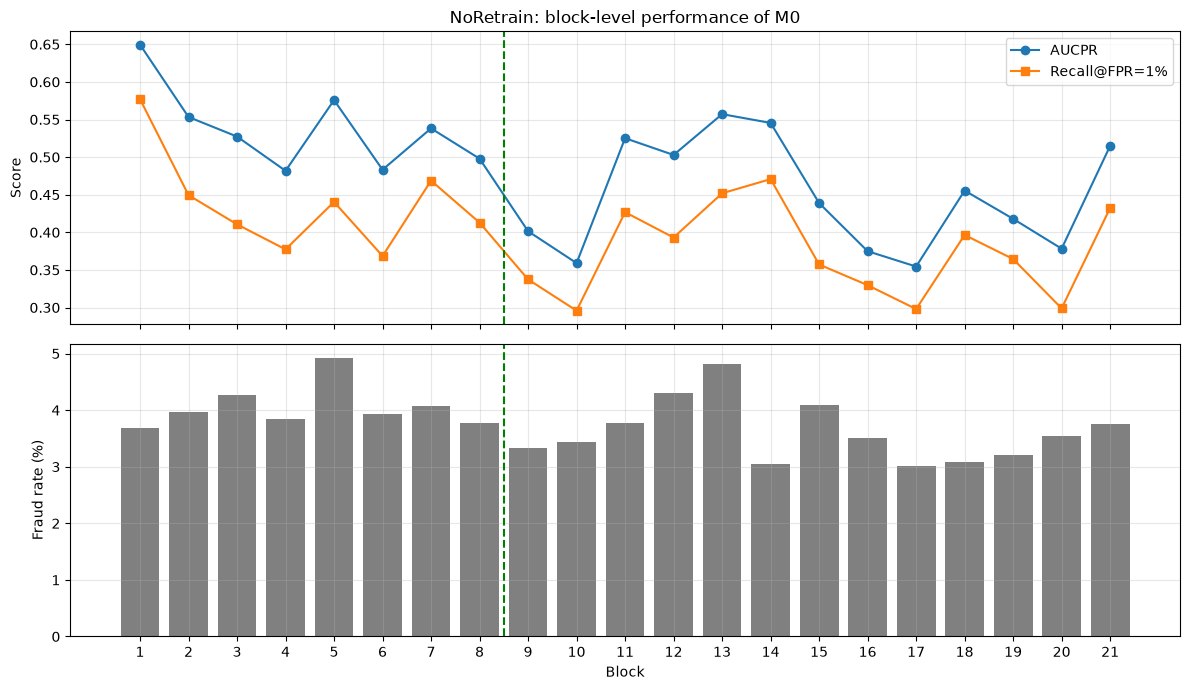

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(noretrain["block_id"], noretrain["aucpr"], marker="o", label="AUCPR")
axes[0].plot(noretrain["block_id"], noretrain["recall_at_fpr_1pct"], marker="s", label="Recall@FPR=1%")
axes[0].set_ylabel("Score")
axes[0].set_title("NoRetrain: block-level performance of M0")
axes[0].legend()

axes[1].bar(noretrain["block_id"], noretrain["fraud_rate_pct"], color="gray")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_xlabel("Block")

for ax in axes:
    ax.axvline(8.5, color="green", linestyle="--")
    ax.grid(alpha=0.3)

axes[1].set_xticks(range(1, 22))

plt.tight_layout()
plt.savefig(FIGURE_DIR / "noretrain_by_block.png", dpi=300, bbox_inches="tight")
plt.show()

The dashed line separates validation (blocks 1–8) from
test (blocks 9–21). AUCPR depends on the fraud rate of each
block, so block-to-block changes should be read together
with the bottom panel and with the other policies on the
same blocks.

## 5. T15 – Periodic Retraining Policy

Retraining is requested at the start of every 1, 2 or 4
blocks (7, 14 or 28 days). Periodic-7d with d = 0 is the
Oracle reference: it sees every label immediately.

Cost is measured by the number of effective retrainings,
the total fit time and the total number of training rows.
Fit time depends on the machine and is only comparable
within this run.

In [12]:
intervals = policy_cfg["policies"]["periodic"]["interval_blocks"]

periodic = pd.concat(
    [
        run_policy(
            PeriodicPolicy(interval),
            banks[delay],
            run_info={"interval_days": 7 * interval},
        )
        for interval in intervals
        for delay in DELAYS
    ],
    ignore_index=True,
)

weekly = periodic.loc[periodic["interval_days"].eq(7)]

for delay, bank in banks.items():
    n = weekly.loc[weekly["label_delay_days"].eq(delay), "retrained"].sum()
    assert n == len(bank.candidate_blocks)

export_report(periodic, REPORT_DIR / "periodic_block_metrics.csv")

display(
    weekly.pivot_table(
        index="block_id", columns="label_delay_days", values="aucpr"
    ).round(4)
)

Saved: /home/claude/fraud-retraining/reports/policies/periodic_block_metrics.csv


label_delay_days,0,7,14,30
block_id,,,,
1,0.6495,0.6495,0.6495,0.6495
2,0.6192,0.5533,0.5533,0.5533
3,0.6083,0.5550,0.5273,0.5273
4,0.6071,0.5488,0.5054,0.4818
5,0.6617,0.6375,0.6116,0.5758
6,0.6158,0.5551,0.5345,0.4720
7,0.6678,0.6112,0.5940,0.5469
8,0.6187,0.5878,0.5673,0.5340
9,0.5084,0.4708,0.4454,0.4109


### Performance and cost

In [13]:
periodic_cost = summarize_cost(
    periodic, ["policy", "interval_days", "label_delay_days"]
)

noretrain_aucpr = noretrain["aucpr"].mean()
oracle_aucpr = periodic_cost.loc[
    periodic_cost["interval_days"].eq(7) & periodic_cost["label_delay_days"].eq(0),
    "mean_aucpr",
].item()

periodic_cost["gain_vs_noretrain"] = periodic_cost["mean_aucpr"] - noretrain_aucpr

periodic_cost["benefit_retained_pct"] = (
    periodic_cost["gain_vs_noretrain"] / (oracle_aucpr - noretrain_aucpr) * 100
)

display(periodic_cost.round(4))

export_report(periodic_cost, REPORT_DIR / "periodic_cost.csv")

,policy,interval_days,label_delay_days,num_retrains,total_fit_seconds,total_train_rows,mean_aucpr,mean_roc_auc,mean_recall_at_fpr_1pct,num_blocks,gain_vs_noretrain,benefit_retained_pct
0,Periodic-14d,14,0,10,223.6089,1900442,0.5772,0.9030,0.4833,21,0.0946,81.5403
1,Periodic-14d,14,7,10,201.4712,1691149,0.5460,0.8923,0.4532,21,0.0634,54.6627
2,Periodic-14d,14,14,9,161.6411,1341995,0.5248,0.8840,0.4344,21,0.0423,36.4370
3,Periodic-14d,14,30,8,98.1459,775906,0.4947,0.8650,0.4088,21,0.0122,10.5136
4,Periodic-28d,28,0,5,110.3232,952519,0.5514,0.8940,0.4602,21,0.0688,59.2925
5,Periodic-28d,28,7,5,99.4226,852441,0.5314,0.8864,0.4426,21,0.0488,42.0897
6,Periodic-28d,28,14,5,90.3127,751586,0.5150,0.8774,0.4300,21,0.0325,27.9813
7,Periodic-28d,28,30,4,45.5771,370506,0.4884,0.8639,0.4043,21,0.0059,5.0808
8,Periodic-7d,7,0,20,456.1034,3794361,0.5986,0.9099,0.5069,21,0.1160,100.0000
9,Periodic-7d,7,7,19,383.8904,3235914,0.5553,0.8964,0.4633,21,0.0728,62.6939


Saved: /home/claude/fraud-retraining/reports/policies/periodic_cost.csv


In [14]:
periodic_summary = summarize_by_phase(
    periodic, ["policy", "interval_days", "label_delay_days"]
)

display(periodic_summary.round(4))

export_report(periodic_summary, REPORT_DIR / "periodic_summary.csv")

,phase,policy,interval_days,label_delay_days,aucpr,roc_auc,recall_at_fpr_1pct,num_blocks
0,all,Periodic-14d,14,0,0.5772,0.9030,0.4833,21
1,all,Periodic-14d,14,7,0.5460,0.8923,0.4532,21
2,all,Periodic-14d,14,14,0.5248,0.8840,0.4344,21
3,all,Periodic-14d,14,30,0.4947,0.8650,0.4088,21
4,all,Periodic-28d,28,0,0.5514,0.8940,0.4602,21
5,all,Periodic-28d,28,7,0.5314,0.8864,0.4426,21
6,all,Periodic-28d,28,14,0.5150,0.8774,0.4300,21
7,all,Periodic-28d,28,30,0.4884,0.8639,0.4043,21
8,all,Periodic-7d,7,0,0.5986,0.9099,0.5069,21
9,all,Periodic-7d,7,7,0.5553,0.8964,0.4633,21


Saved: /home/claude/fraud-retraining/reports/policies/periodic_summary.csv


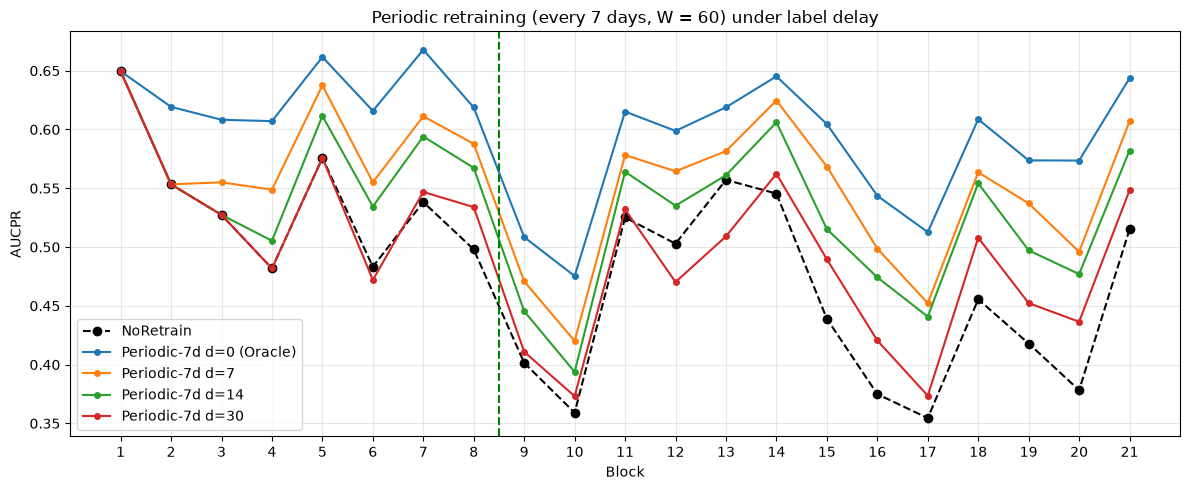

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(noretrain["block_id"], noretrain["aucpr"], color="black", linestyle="--", marker="o", label="NoRetrain")

for delay in DELAYS:
    sub = weekly.loc[weekly["label_delay_days"].eq(delay)]
    label = "Periodic-7d d=0 (Oracle)" if delay == 0 else f"Periodic-7d d={delay}"
    ax.plot(sub["block_id"], sub["aucpr"], marker="o", markersize=4, label=label)

ax.axvline(8.5, color="green", linestyle="--")
ax.set_xticks(range(1, 22))
ax.set_xlabel("Block")
ax.set_ylabel("AUCPR")
ax.set_title("Periodic retraining (every 7 days, W = 60) under label delay")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(FIGURE_DIR / "periodic_aucpr_by_block.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. T16 – Random-k Retraining Policy

Random-k retrains at exactly k blocks drawn uniformly
without replacement. Blocks are drawn only from blocks where
new labels exist, so every draw is an effective retraining
and k is the real budget.

Each (d, k) pair is repeated over many seeds. Models come
from the same banks, so the seeds only change the retraining
times.

In [16]:
random_cfg = policy_cfg["policies"]["random_k"]

seeds = [random_cfg["base_seed"] + i for i in range(random_cfg["num_seeds"])]

random_runs = []

for delay in random_cfg["label_delay_days"]:
    for budget in random_cfg["budgets"]:
        for seed in seeds:
            result = run_policy(
                RandomKPolicy(budget, seed),
                banks[delay],
                run_info={"budget_k": budget, "seed": seed},
            )
            assert result["retrained"].sum() == budget
            random_runs.append(result)

random_k = pd.concat(random_runs, ignore_index=True)

print("Runs:", len(random_runs))
print("Rows:", len(random_k))

export_report(random_k, REPORT_DIR / "random_k_block_metrics.csv")

Runs: 450
Rows: 9450
Saved: /home/claude/fraud-retraining/reports/policies/random_k_block_metrics.csv


### Distribution over seeds

In [17]:
random_cost = summarize_cost(
    random_k, ["policy", "label_delay_days", "budget_k", "seed"]
)

random_summary = (
    random_cost.groupby(["label_delay_days", "budget_k"])
    .agg(
        num_seeds=("seed", "nunique"),
        mean_aucpr=("mean_aucpr", "mean"),
        std_aucpr=("mean_aucpr", "std"),
        p05_aucpr=("mean_aucpr", lambda x: x.quantile(0.05)),
        p50_aucpr=("mean_aucpr", "median"),
        p95_aucpr=("mean_aucpr", lambda x: x.quantile(0.95)),
        mean_roc_auc=("mean_roc_auc", "mean"),
        mean_recall_at_fpr_1pct=("mean_recall_at_fpr_1pct", "mean"),
        mean_fit_seconds=("total_fit_seconds", "mean"),
    )
    .reset_index()
)

random_summary["gain_vs_noretrain"] = random_summary["mean_aucpr"] - noretrain_aucpr

display(random_summary.round(4))

export_report(random_cost, REPORT_DIR / "random_k_runs.csv")
export_report(random_summary, REPORT_DIR / "random_k_summary.csv")

,label_delay_days,budget_k,num_seeds,mean_aucpr,std_aucpr,p05_aucpr,p50_aucpr,p95_aucpr,mean_roc_auc,mean_recall_at_fpr_1pct,mean_fit_seconds,gain_vs_noretrain
0,7,5,50,0.5275,0.0052,0.5175,0.5284,0.5340,0.8826,0.4374,99.7442,0.0450
1,7,10,50,0.5420,0.0029,0.5373,0.5424,0.5457,0.8903,0.4509,201.2959,0.0595
2,7,15,50,0.5506,0.0015,0.5486,0.5509,0.5528,0.8942,0.4587,301.3694,0.0681
3,14,5,50,0.5138,0.0057,0.5057,0.5145,0.5215,0.8759,0.4255,89.3157,0.0312
4,14,10,50,0.5243,0.0025,0.5208,0.5244,0.5288,0.8823,0.4349,180.4907,0.0417
5,14,15,50,0.5302,0.0010,0.5286,0.5303,0.5317,0.8854,0.4405,271.4581,0.0477
6,30,5,50,0.4917,0.0053,0.4838,0.4926,0.4985,0.8621,0.4071,62.0870,0.0091
7,30,10,50,0.4952,0.0019,0.4924,0.4956,0.4978,0.8653,0.4089,126.8195,0.0127
8,30,15,50,0.4963,0.0005,0.4955,0.4962,0.4972,0.8663,0.4089,192.4225,0.0137


Saved: /home/claude/fraud-retraining/reports/policies/random_k_runs.csv
Saved: /home/claude/fraud-retraining/reports/policies/random_k_summary.csv


### Budget versus performance

Each box shows the mean AUCPR over 21 blocks across seeds
for one budget k. Periodic-28d/14d/7d are placed at their
own number of retrainings, and NoRetrain at zero.

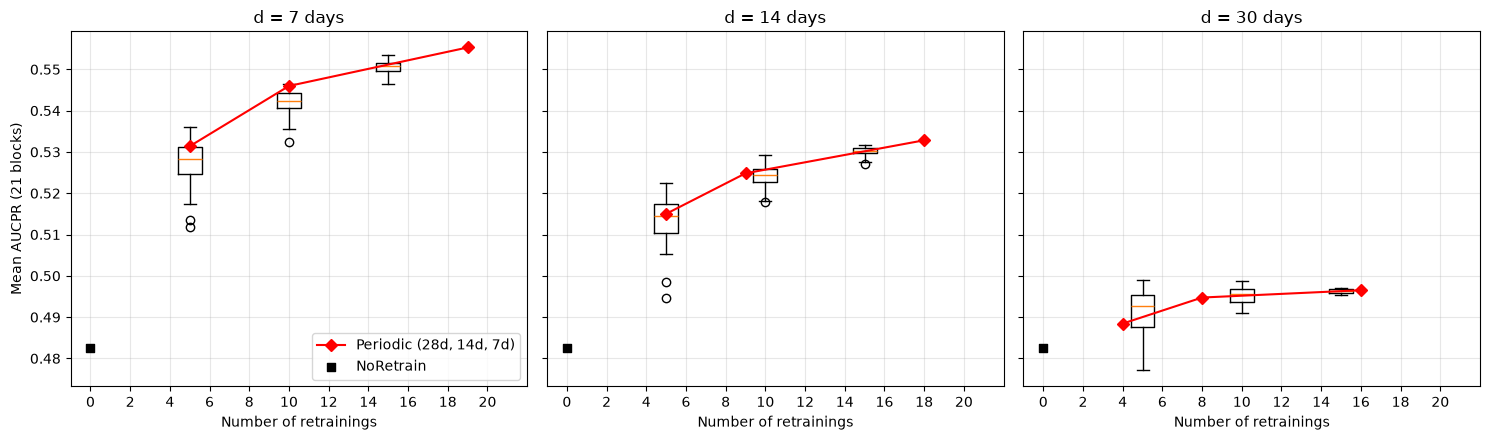

In [18]:
random_delays = random_cfg["label_delay_days"]

fig, axes = plt.subplots(1, len(random_delays), figsize=(15, 4.5), sharey=True)

for ax, delay in zip(axes, random_delays):

    runs = random_cost.loc[random_cost["label_delay_days"].eq(delay)]

    budgets = random_cfg["budgets"]

    ax.boxplot(
        [runs.loc[runs["budget_k"].eq(k), "mean_aucpr"] for k in budgets],
        positions=budgets,
        widths=1.2,
        manage_ticks=False,
    )

    periodic_rows = periodic_cost.loc[periodic_cost["label_delay_days"].eq(delay)].sort_values("num_retrains")

    ax.plot(periodic_rows["num_retrains"], periodic_rows["mean_aucpr"], color="red", marker="D", zorder=3, label="Periodic (28d, 14d, 7d)")
    ax.scatter(0, noretrain_aucpr, color="black", marker="s", zorder=3, label="NoRetrain")

    ax.set_xlim(-1, 22)
    ax.set_xticks(range(0, 22, 2))
    ax.set_xlabel("Number of retrainings")
    ax.set_title(f"d = {delay} days")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean AUCPR (21 blocks)")
axes[0].legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "random_k_budget.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Baseline Comparison

In [19]:
comparison = pd.concat(
    [
        summarize_cost(noretrain.assign(label_delay_days=np.nan), ["policy", "label_delay_days"]),
        periodic_cost.drop(columns=["gain_vs_noretrain", "benefit_retained_pct"]),
        random_cost.groupby(["policy", "label_delay_days", "budget_k"])
        .mean(numeric_only=True)
        .drop(columns=["seed"])
        .reset_index(),
    ],
    ignore_index=True,
)

comparison = comparison[
    [
        "policy",
        "interval_days",
        "label_delay_days",
        "budget_k",
        "num_retrains",
        "total_fit_seconds",
        "mean_aucpr",
        "mean_roc_auc",
        "mean_recall_at_fpr_1pct",
    ]
]

display(comparison.round(4))

export_report(comparison, REPORT_DIR / "baseline_comparison.csv")

,policy,interval_days,label_delay_days,budget_k,num_retrains,total_fit_seconds,mean_aucpr,mean_roc_auc,mean_recall_at_fpr_1pct
0,NoRetrain,NaN,NaN,NaN,0.0,0.0000,0.4825,0.8524,0.3980
1,Periodic-14d,14.0,0.0,NaN,10.0,223.6089,0.5772,0.9030,0.4833
2,Periodic-14d,14.0,7.0,NaN,10.0,201.4712,0.5460,0.8923,0.4532
3,Periodic-14d,14.0,14.0,NaN,9.0,161.6411,0.5248,0.8840,0.4344
4,Periodic-14d,14.0,30.0,NaN,8.0,98.1459,0.4947,0.8650,0.4088
5,Periodic-28d,28.0,0.0,NaN,5.0,110.3232,0.5514,0.8940,0.4602
6,Periodic-28d,28.0,7.0,NaN,5.0,99.4226,0.5314,0.8864,0.4426
7,Periodic-28d,28.0,14.0,NaN,5.0,90.3127,0.5150,0.8774,0.4300
8,Periodic-28d,28.0,30.0,NaN,4.0,45.5771,0.4884,0.8639,0.4043
9,Periodic-7d,7.0,0.0,NaN,20.0,456.1034,0.5986,0.9099,0.5069


Saved: /home/claude/fraud-retraining/reports/policies/baseline_comparison.csv


## 8. Validation Checks

In [20]:
checks = pd.DataFrame(
    [
        {"check": "21 evaluation blocks", "passed": noretrain["block_id"].nunique() == 21},
        {"check": "M0 identical across delays", "passed": len(m0_signatures) == 1},
        {"check": "NoRetrain never retrains", "passed": not noretrain["retrained"].any()},
        {
            "check": "Periodic retrains at every block with new labels",
            "passed": all(
                periodic_cost.loc[
                    periodic_cost["interval_days"].eq(7) & periodic_cost["label_delay_days"].eq(d),
                    "num_retrains",
                ].item()
                == len(bank.candidate_blocks)
                for d, bank in banks.items()
            ),
        },
        {
            "check": "Random-k retrains exactly k times",
            "passed": (random_cost["num_retrains"] == random_cost["budget_k"]).all(),
        },
    ]
)

display(checks)

export_report(checks, REPORT_DIR / "policy_validation.csv")

assert checks["passed"].all()

,check,passed
0,21 evaluation blocks,True
1,M0 identical across delays,True
2,NoRetrain never retrains,True
3,Periodic retrains at every block with new labels,True
4,Random-k retrains exactly k times,True


Saved: /home/claude/fraud-retraining/reports/policies/policy_validation.csv


In [21]:
metadata = {
    "stage": "baseline_policies",
    "tasks": ["T14 NoRetrain", "T15 Periodic", "T16 Random-k"],
    "feature_set": exp_cfg["feature_set"],
    "window_days": WINDOW_DAYS,
    "label_delay_days": DELAYS,
    "evaluation_phases": EVAL_PHASES,
    "num_eval_blocks": len(eval_blocks),
    "model": policy_cfg["model"],
    "periodic_interval_blocks": intervals,
    "random_k": random_cfg,
    "pandas_version": pd.__version__,
}

with open(REPORT_DIR / "policy_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("STEP 6: BASELINE POLICIES COMPLETED")

STEP 6: BASELINE POLICIES COMPLETED
